# Barrier sets give the same trend
Mean olefin length vs T, 50 bar, cat = 1e-2, s = 5, 1 h, pocket crowding.

`tetra`: Flory-Schulz approximation, tetramerization barriers for all steps. `bep`: BEP barriers. `legacy`: original list.

s = 5: average open window for ~C10.

Only the barrier set differs. Absolute values differ, the trends match.

In [1]:
import sys
sys.path.insert(0, '../scripts')
import warnings; warnings.filterwarnings('ignore')
import km_common as km
import pandas as pd
import matplotlib.pyplot as plt

P = 50                  # bar
SITE_FRAC = 1.0         # cat = 1e-2
S = 5.0                 # open window for ~C10
T = list(range(300, 491, 10))
assert all(km.network_consistency(t, P)[0] for t in T)   # network valid
VARIANTS = {'tetra': dict(elim_map='tetra'),
            'bep': dict(elim_map='bep'),
            'legacy': dict(elim_map='legacy')}
CASES = {'batch, no diffusion limit': ('batch', None),
         'batch, 1000 um': ('batch', 1e6),
         'flow, 1000 um': ('flow', 1e6)}

In [2]:
# mean n, 1 h
rows = []
for case, (mode, size) in CASES.items():
    for name, kw in VARIANTS.items():
        for t in T:
            dist, _ = km.simulate(t, P, mode=mode, particle_nm=size, model='corrected', hours=1.0, n_steps=300,
                                  crowding='pocket', s_pocket=S, site_frac=SITE_FRAC, check_network=None, **kw)
            rows.append((case, name, t, km.mean_length(dist)))
res = pd.DataFrame(rows, columns=['case', 'variant', 'T', 'mean_n'])
res.pivot_table(index=['case', 'variant'], columns='T', values='mean_n').round(1)

T                                   300   310   320   330   340   350   360  \
case                      variant                                             
batch, 1000 um            bep      11.2   9.8  12.1  12.9  11.0   9.6   9.0   
                          legacy   15.9  15.6  15.3  14.5  12.8  11.2  10.2   
                          tetra    15.9  15.6  15.3  14.4  12.6  10.9   9.9   
batch, no diffusion limit bep      11.3  10.1  11.0  12.1  13.1  13.1  11.7   
                          legacy   15.9  15.8  15.9  15.9  16.0  16.0  16.0   
                          tetra    15.9  15.7  15.8  15.9  16.0  16.0  16.0   
flow, 1000 um             bep      11.2   9.0   7.8   7.8   8.3   8.2   8.3   
                          legacy   15.9  15.5  14.7  13.4  11.7  10.3   9.6   
                          tetra    15.9  15.6  14.7  13.2  11.4   9.9   9.2   

T                                   370   380   390   400   410   420   430  \
case                      variant                                             
batch, 1000 um            bep       8.6   8.3   8.1   7.8   7.6   7.4   7.6   
                          legacy    9.8   9.8   9.8   9.8   9.9   9.9  10.0   
                          tetra     9.5   9.5   9.4   9.4   9.5   9.6   9.9   
batch, no diffusion limit bep      10.4   9.2   8.2   7.3   6.6   6.1   5.8   
                          legacy   16.0  16.0  15.4  13.7  12.0  10.6   9.6   
                          tetra    16.0  15.6  13.9  12.1  10.6   9.4   9.0   
flow, 1000 um             bep       8.3   8.5   8.6   8.8   8.9   9.1   9.2   
                          legacy    9.3   9.3   9.4   9.4   9.5   9.6   9.6   
                          tetra     9.0   9.0   9.0   9.1   9.2   9.3   9.3   

T                                   440   450   460   470   480   490  
case                      variant                                      
batch, 1000 um            bep       8.4  10.6  13.3  14.4  14.7  14.9  
                          legacy   10.5  12.0  13.5  14.4  14.8  14.9  
                          tetra    11.3  13.5  14.3  15.1  15.3  15.3  
batch, no diffusion limit bep       5.9   6.8   9.4  12.9  13.5  12.9  
                          legacy    9.1   9.9  12.2  13.9  13.8  13.4  
                          tetra    10.0  13.0  14.7  14.8  14.5  14.2  
flow, 1000 um             bep       9.4   9.5   9.6   9.8  10.0  10.1  
                          legacy    9.8   9.9   9.9  10.1  10.2  10.3  
                          tetra     9.5   9.6   9.7   9.9  10.0  10.1

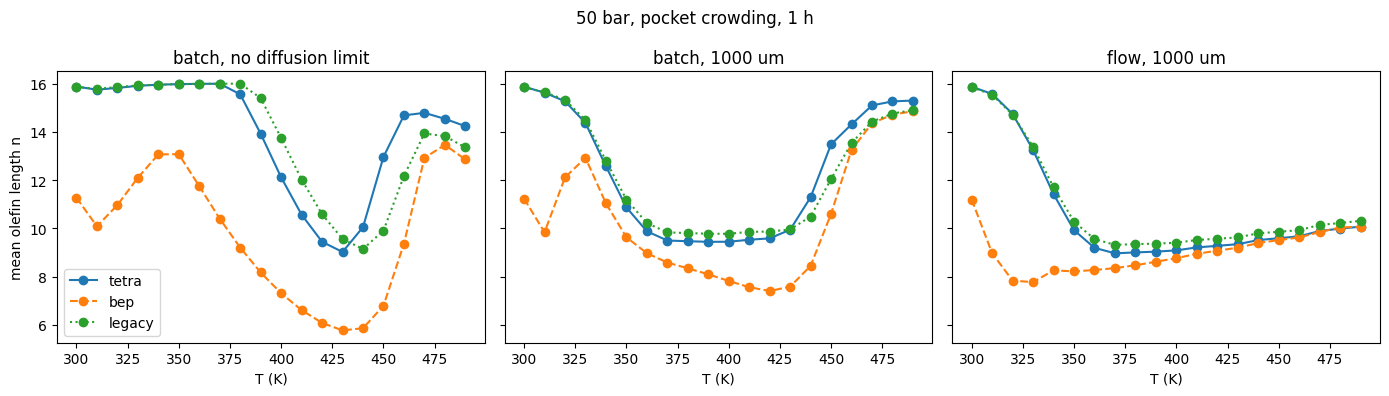

In [3]:
# n vs T
styles = {'tetra': ('C0', '-'), 'bep': ('C1', '--'), 'legacy': ('C2', ':')}
fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (case, g) in zip(axs, res.groupby('case', sort=False)):
    for name, h in g.groupby('variant', sort=False):
        ax.plot(h['T'], h['mean_n'], color=styles[name][0], ls=styles[name][1], marker='o', label=name)
    ax.set_title(case); ax.set_xlabel('T (K)')
axs[0].set_ylabel('mean olefin length n'); axs[0].legend()
fig.suptitle(f'{P} bar, pocket crowding, 1 h')
plt.tight_layout()